In [27]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate
)

from sklearn.linear_model import (
    Ridge,
    Lasso,
    ElasticNet
)

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)

In [29]:
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = PROJECT_ROOT / "data" / "raw"
MODELS_PATH = PROJECT_ROOT / "models"
SUBMISSIONS_PATH = PROJECT_ROOT / "submissions"

MODELS_PATH.mkdir(exist_ok=True)
SUBMISSIONS_PATH.mkdir(exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("Data path:", DATA_PATH)

Project root: c:\Users\r.carrillo\OneDrive - MultiSafepay\Desktop\kaggle house price
Data path: c:\Users\r.carrillo\OneDrive - MultiSafepay\Desktop\kaggle house price\data\raw


In [30]:
from src.features import add_features
from src.preprocessing import handle_missing_values

In [31]:
train = pd.read_csv(
    DATA_PATH / "train.csv"
)

test = pd.read_csv(
    DATA_PATH / "test.csv"
)

print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (1168, 81)
Test shape: (292, 80)


In [32]:
X = train.drop(
    columns=["SalePrice", "SalePrice_log"],
    errors="ignore"
).copy()

y = np.log1p(train["SalePrice"])

X_test = test.copy()

In [33]:
X = add_features(X)
X_test = add_features(X_test)

X = handle_missing_values(X)
X_test = handle_missing_values(X_test)

In [34]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [35]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Variables numéricas:", len(numeric_features))
print("Variables categóricas:", len(categorical_features))

Variables numéricas: 44
Variables categóricas: 43


C:\Users\r.carrillo\AppData\Local\Temp\ipykernel_17788\2486587341.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [36]:
linear_numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])
linear_categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="Missing"
        )
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])
linear_preprocessor = ColumnTransformer([
    (
        "numeric",
        linear_numeric_pipeline,
        numeric_features
    ),
    (
        "categorical",
        linear_categorical_pipeline,
        categorical_features
    )
])

In [37]:
tree_numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    )
])

tree_categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="Missing"
        )
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

tree_preprocessor = ColumnTransformer([
    (
        "numeric",
        tree_numeric_pipeline,
        numeric_features
    ),
    (
        "categorical",
        tree_categorical_pipeline,
        categorical_features
    )
])

In [38]:
ridge_pipeline = Pipeline([
    (
        "preprocessor",
        linear_preprocessor
    ),
    (
        "model",
        Ridge(alpha=10.0)
    )
])

In [39]:
lasso_pipeline = Pipeline([
    (
        "preprocessor",
        linear_preprocessor
    ),
    (
        "model",
        Lasso(
            alpha=0.001,
            max_iter=30000
        )
    )
])

In [40]:
elasticnet_pipeline = Pipeline([
    (
        "preprocessor",
        linear_preprocessor
    ),
    (
        "model",
        ElasticNet(
            alpha=0.001,
            l1_ratio=0.5,
            max_iter=30000
        )
    )
])

In [41]:
random_forest_pipeline = Pipeline([
    (
        "preprocessor",
        tree_preprocessor
    ),
    (
        "model",
        RandomForestRegressor(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        )
    )
])

In [42]:
gradient_boosting_pipeline = Pipeline([
    (
        "preprocessor",
        tree_preprocessor
    ),
    (
        "model",
        GradientBoostingRegressor(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        )
    )
])

In [43]:
models = {
    "Ridge": ridge_pipeline,
    "Lasso": lasso_pipeline,
    "ElasticNet": elasticnet_pipeline,
    "Random Forest": random_forest_pipeline,
    "Gradient Boosting": gradient_boosting_pipeline
}

In [44]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [45]:
scoring = {
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "R2": "r2"
}

In [46]:
results = []

for model_name, model in models.items():

    print(f"Evaluando: {model_name}")

    start_time = time.time()

    cv_results = cross_validate(
        estimator=model,
        X=X,
        y=y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=True
    )

    elapsed_time = time.time() - start_time

    train_rmse = -cv_results["train_RMSE"]
    validation_rmse = -cv_results["test_RMSE"]
    validation_mae = -cv_results["test_MAE"]
    validation_r2 = cv_results["test_R2"]

    results.append({
        "Model": model_name,
        "Train_RMSE_mean": train_rmse.mean(),
        "CV_RMSE_mean": validation_rmse.mean(),
        "CV_RMSE_std": validation_rmse.std(),
        "CV_MAE_mean": validation_mae.mean(),
        "CV_R2_mean": validation_r2.mean(),
        "Overfitting_gap": (
            validation_rmse.mean()
            - train_rmse.mean()
        ),
        "Time_seconds": elapsed_time
    })

    print(
        f"Train RMSE medio: "
        f"{train_rmse.mean():.5f}"
    )

    print(
        f"CV RMSE medio: "
        f"{validation_rmse.mean():.5f}"
    )

    print(
        f"CV RMSE desviación: "
        f"{validation_rmse.std():.5f}"
    )

    print(
        f"Tiempo: "
        f"{elapsed_time:.2f} segundos"
    )

    print("-" * 50)

Evaluando: Ridge
Train RMSE medio: 0.10708
CV RMSE medio: 0.14297
CV RMSE desviación: 0.02917
Tiempo: 30.73 segundos
--------------------------------------------------
Evaluando: Lasso
Train RMSE medio: 0.11260
CV RMSE medio: 0.14027
CV RMSE desviación: 0.03342
Tiempo: 2.17 segundos
--------------------------------------------------
Evaluando: ElasticNet
Train RMSE medio: 0.10517
CV RMSE medio: 0.14026
CV RMSE desviación: 0.03202
Tiempo: 2.39 segundos
--------------------------------------------------
Evaluando: Random Forest
Train RMSE medio: 0.05348
CV RMSE medio: 0.14361
CV RMSE desviación: 0.01484
Tiempo: 4.21 segundos
--------------------------------------------------
Evaluando: Gradient Boosting
Train RMSE medio: 0.05972
CV RMSE medio: 0.12729
CV RMSE desviación: 0.01557
Tiempo: 3.16 segundos
--------------------------------------------------


In [47]:
results_df = pd.DataFrame(results)

results_df = (
    results_df
    .sort_values("CV_RMSE_mean")
    .reset_index(drop=True)
)

results_df

,Model,Train_RMSE_mean,CV_RMSE_mean,CV_RMSE_std,CV_MAE_mean,CV_R2_mean,Overfitting_gap,Time_seconds
0,Gradient Boosting,0.059717,0.127291,0.015572,0.085684,0.893349,0.067573,3.157808
1,ElasticNet,0.105168,0.140264,0.032024,0.087771,0.867288,0.035097,2.389058
2,Lasso,0.112597,0.140268,0.033425,0.088559,0.866991,0.027671,2.171321
3,Ridge,0.107082,0.142970,0.029173,0.091710,0.863115,0.035887,30.731141
4,Random Forest,0.053485,0.143612,0.014839,0.097861,0.864440,0.090127,4.207422


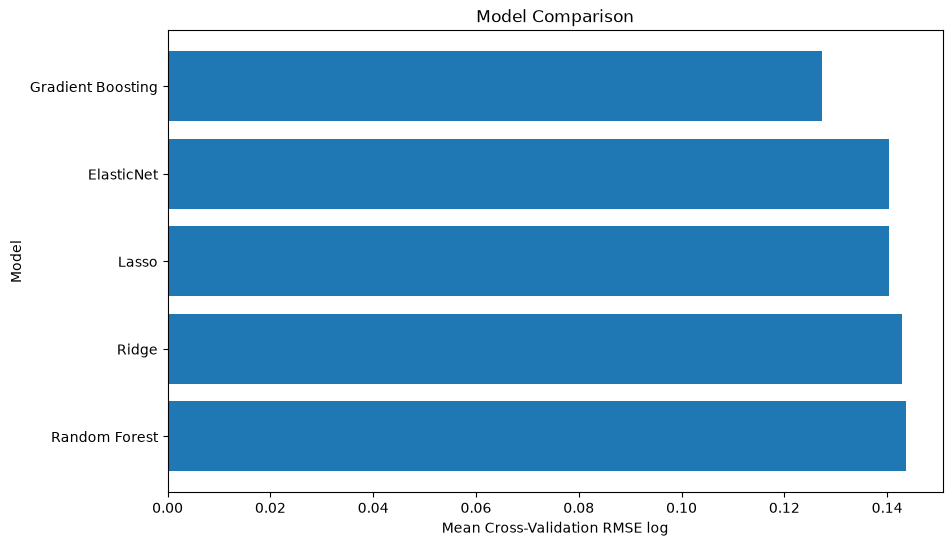

In [48]:
plt.figure(figsize=(10, 6))

plt.barh(
    results_df["Model"],
    results_df["CV_RMSE_mean"]
)

plt.xlabel("Mean Cross-Validation RMSE log")
plt.ylabel("Model")
plt.title("Model Comparison")

plt.gca().invert_yaxis()

plt.show()

In [49]:
best_model_name = results_df.loc[
    0,
    "Model"
]

best_model = models[
    best_model_name
]

best_cv_rmse = results_df.loc[
    0,
    "CV_RMSE_mean"
]

print("Mejor modelo:", best_model_name)
print(f"Mejor CV RMSE: {best_cv_rmse:.5f}")

Mejor modelo: Gradient Boosting
Mejor CV RMSE: 0.12729


In [50]:
best_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](87,)","['Id','MSSubClass','MSZoning',...,'HasGarage','HasBasement','HasFireplace']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,87
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This s

In [51]:
valid_predictions_log = best_model.predict(
    X_valid
)

In [52]:
rmse_log = root_mean_squared_error(
    y_valid,
    valid_predictions_log
)

print(f"Validation RMSE log: {rmse_log:.5f}")

Validation RMSE log: 0.13033


In [53]:
actual_prices = np.expm1(
    y_valid
)

predicted_prices = np.expm1(
    valid_predictions_log
)

In [54]:
mae_price = mean_absolute_error(
    actual_prices,
    predicted_prices
)

mape_price = (
    mean_absolute_percentage_error(
        actual_prices,
        predicted_prices
    )
    * 100
)

r2_price = r2_score(
    actual_prices,
    predicted_prices
)

In [55]:
print("Modelo:", best_model_name)
print(f"RMSE log: {rmse_log:.5f}")
print(f"MAE en precio: {mae_price:,.2f}")
print(f"MAPE: {mape_price:.2f}%")
print(f"R² en precio: {r2_price:.4f}")

Modelo: Gradient Boosting
RMSE log: 0.13033
MAE en precio: 15,393.95
MAPE: 9.07%
R² en precio: 0.9138


In [56]:
comparison = pd.DataFrame({
    "ActualPrice": actual_prices,
    "PredictedPrice": predicted_prices
})

In [57]:
comparison["AbsoluteError"] = (
    comparison["ActualPrice"]
    - comparison["PredictedPrice"]
).abs()

comparison["PercentageError"] = (
    comparison["AbsoluteError"]
    / comparison["ActualPrice"]
    * 100
)

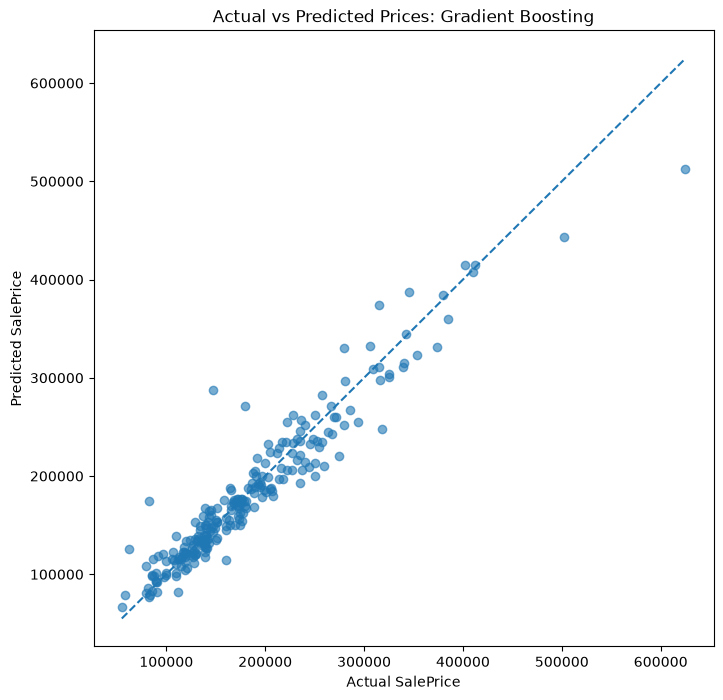

In [58]:
plt.figure(figsize=(8, 8))

plt.scatter(
    actual_prices,
    predicted_prices,
    alpha=0.6
)

minimum_price = min(
    actual_prices.min(),
    predicted_prices.min()
)

maximum_price = max(
    actual_prices.max(),
    predicted_prices.max()
)

plt.plot(
    [minimum_price, maximum_price],
    [minimum_price, maximum_price],
    linestyle="--"
)

plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title(
    f"Actual vs Predicted Prices: {best_model_name}"
)

plt.show()